# Dimensionality Reduction: PCA & t-SNE

This notebook is a hands-on, visual study of two of the most important techniques for
reducing and visualizing high-dimensional data:

1. **PCA (Principal Component Analysis)** — a *linear* technique that finds new axes
   (principal components) that capture the maximum variance in the data.
2. **t-SNE (t-distributed Stochastic Neighbor Embedding)** — a *non-linear* technique
   that tries to preserve the **local neighborhood structure** of the data so that
   similar points stay close together in the low-dimensional map.

We will use the classic **Digits dataset** (8x8 images of handwritten digits 0-9,
64 features per sample) built into scikit-learn — no external download needed — plus
a quick look at the **Iris** dataset for a gentler, low-dimensional warm-up.

**What you'll learn / see:**
- Why high-dimensional data is hard to visualize (the "curse of dimensionality")
- How PCA finds directions of maximum variance, scree plots, explained variance
- 2D / 3D PCA projections, and image reconstruction from fewer components
- The intuition behind t-SNE (neighbors, perplexity, non-linearity)
- Side-by-side comparison of PCA vs t-SNE
- The effect of the *perplexity* hyperparameter on t-SNE output


## 1. Setup — imports & style

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (enables 3D projection)

from sklearn.datasets import load_digits, load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
RNG = 42
np.random.seed(RNG)

print("Libraries loaded ✔")


Libraries loaded ✔


## 2. The dataset — `sklearn.datasets.load_digits`

Each sample is an **8x8 grayscale image** of a handwritten digit (0-9), flattened into
a **64-dimensional** feature vector (pixel intensities 0-16). This is a perfect
playground for dimensionality reduction: we *know* the true labels (0-9), so we can
color our 2D/3D projections by digit and visually check whether PCA / t-SNE manage to
separate the classes using no label information at all (both are **unsupervised**).


In [2]:
digits = load_digits()
X, y = digits.data, digits.target

print("Feature matrix shape:", X.shape)   # (n_samples, 64)
print("Labels shape:", y.shape)
print("Classes:", np.unique(y))
print("Pixel value range:", X.min(), "-", X.max())

pd.DataFrame(X).describe().T.head()


Feature matrix shape: (1797, 64)
Labels shape: (1797,)
Classes: [0 1 2 3 4 5 6 7 8 9]
Pixel value range: 0.0 - 16.0


,count,mean,std,min,25%,50%,75%,max
0,1797.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
1,1797.0,0.303840,0.907192,0.0,0.0,0.0,0.0,8.0
2,1797.0,5.204786,4.754826,0.0,1.0,4.0,9.0,16.0
3,1797.0,11.835838,4.248842,0.0,10.0,13.0,15.0,16.0
4,1797.0,11.848080,4.287388,0.0,10.0,13.0,15.0,16.0


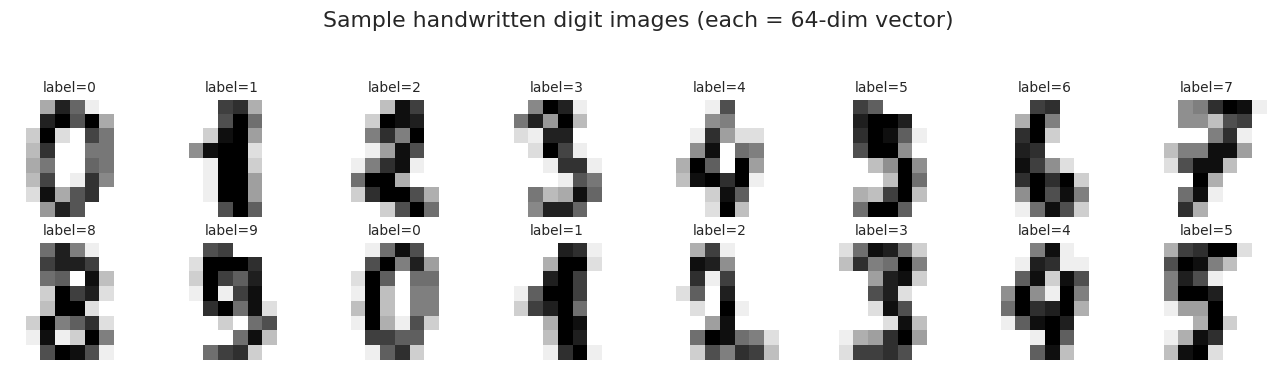

In [3]:
# Peek at a few raw digit images (each is 8x8 = 64 pixels)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[i], cmap="gray_r")
    ax.set_title(f"label={digits.target[i]}", fontsize=9)
    ax.axis("off")
fig.suptitle("Sample handwritten digit images (each = 64-dim vector)", y=1.05)
plt.tight_layout()
plt.show()


## 3. Why reduce dimensionality?

- **Visualization**: humans can only *see* in 2D / 3D. A 64-dim (or 1000-dim) dataset
  can't be plotted directly.
- **Curse of dimensionality**: distances become less meaningful, models overfit more
  easily, and computation gets expensive as dimensions grow.
- **Noise reduction / compression**: many dimensions are redundant or correlated;
  we can often capture most of the "signal" with far fewer numbers.
- **Speed**: fewer features → faster downstream models.

Let's start with **PCA**.


## 4. PCA — Intuition

PCA looks for the directions (**principal components**) along which the data varies
the *most*, and rotates the coordinate system to align with those directions. The
first principal component (PC1) captures the most variance, PC2 (orthogonal to PC1)
the next most, and so on.

Formally, PCA finds the eigenvectors of the data's covariance matrix; the eigenvalues
tell us how much variance each component explains. It's a **linear**, deterministic,
and very fast technique.

Steps:
1. Standardize the data (mean 0, unit variance) — important since PCA is scale-sensitive.
2. Compute principal components.
3. Project the data onto the top-k components.


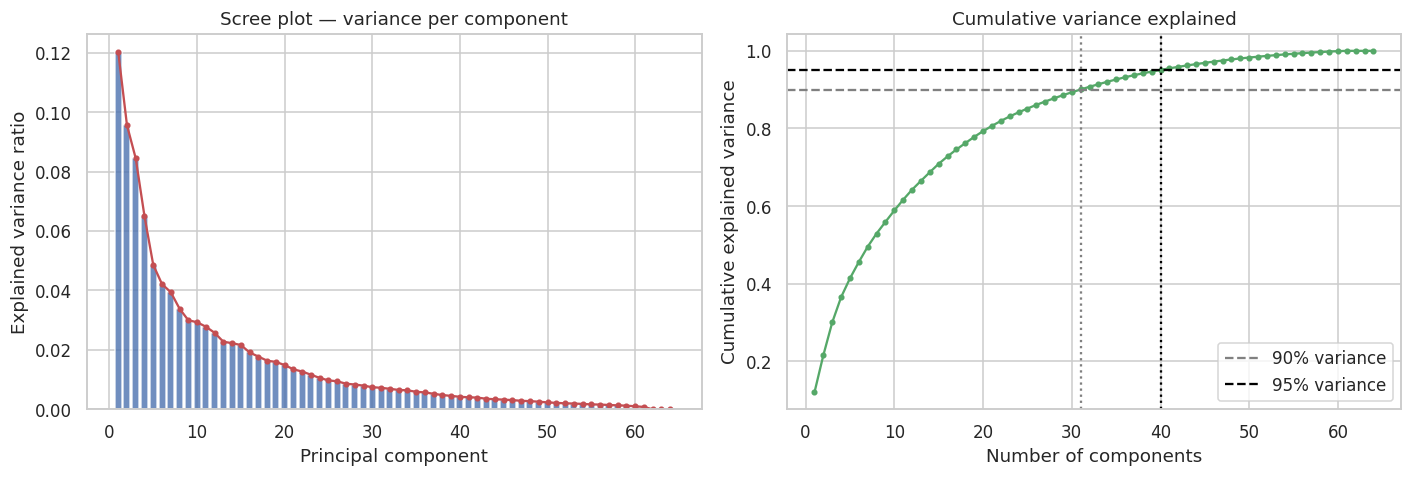

Components needed for 90% variance: 31
Components needed for 95% variance: 40
(Original dimensionality: 64)


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit PCA keeping ALL components first, just to study variance
pca_full = PCA(random_state=RNG)
pca_full.fit(X_scaled)

explained = pca_full.explained_variance_ratio_
cum_explained = np.cumsum(explained)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Scree plot
axes[0].bar(range(1, len(explained) + 1), explained, color="#4C72B0", alpha=0.8)
axes[0].plot(range(1, len(explained) + 1), explained, color="#C44E52", marker="o", ms=3)
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Explained variance ratio")
axes[0].set_title("Scree plot — variance per component")

# Cumulative variance
axes[1].plot(range(1, len(cum_explained) + 1), cum_explained, color="#55A868", marker="o", ms=3)
axes[1].axhline(0.90, color="gray", linestyle="--", label="90% variance")
axes[1].axhline(0.95, color="black", linestyle="--", label="95% variance")
n90 = np.argmax(cum_explained >= 0.90) + 1
n95 = np.argmax(cum_explained >= 0.95) + 1
axes[1].axvline(n90, color="gray", linestyle=":")
axes[1].axvline(n95, color="black", linestyle=":")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative explained variance")
axes[1].set_title("Cumulative variance explained")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Components needed for 90% variance: {n90}")
print(f"Components needed for 95% variance: {n95}")
print(f"(Original dimensionality: {X.shape[1]})")


**Takeaway:** we can compress the 64 original pixel dimensions down to roughly a
few dozen components and still keep ~90-95% of the information — a solid compression
ratio, achieved purely by finding directions of maximum variance.

### 4.1 Projecting onto 2 components — the classic PCA scatter plot

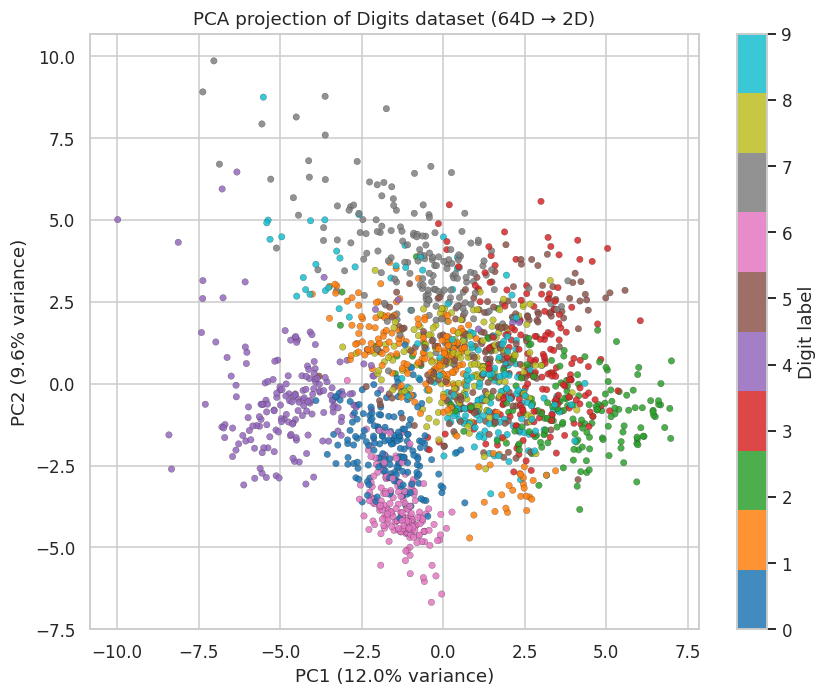

In [5]:
pca_2d = PCA(n_components=2, random_state=RNG)
X_pca_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(8, 6.5))
scatter = plt.scatter(
    X_pca_2d[:, 0], X_pca_2d[:, 1],
    c=y, cmap="tab10", s=18, alpha=0.85, edgecolor="k", linewidth=0.15
)
plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("PCA projection of Digits dataset (64D → 2D)")
cbar = plt.colorbar(scatter, ticks=range(10))
cbar.set_label("Digit label")
plt.tight_layout()
plt.show()


Notice that with only **2 components** some digit clusters already separate
reasonably well (e.g. 0 and 4 vs the rest), but many classes still overlap — 2 linear
directions simply can't capture all the variation needed to fully separate 10 digit
classes. Let's also look in 3D.

### 4.2 3D PCA projection

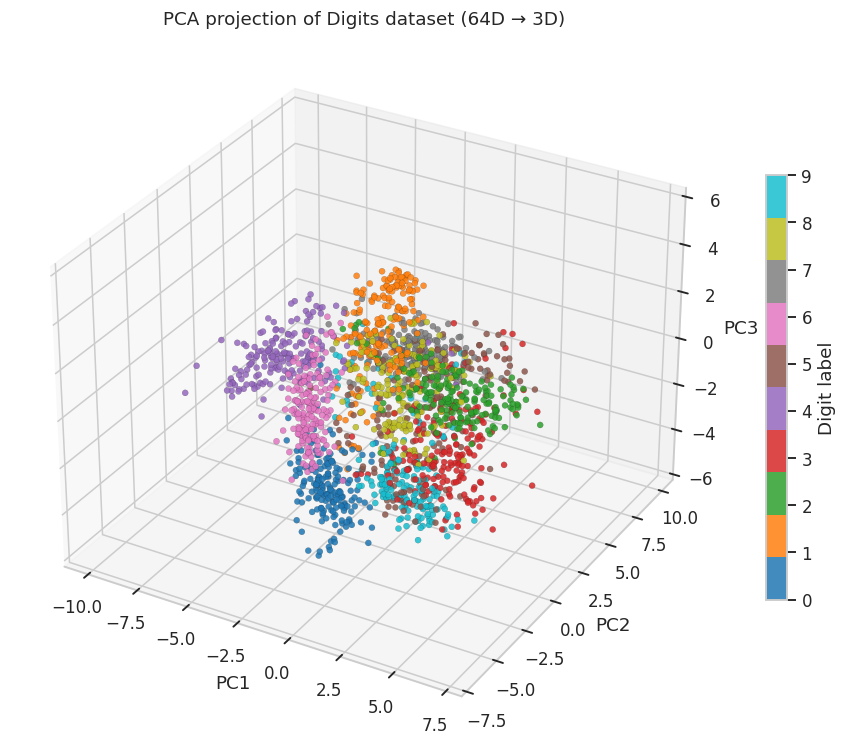

In [6]:
pca_3d = PCA(n_components=3, random_state=RNG)
X_pca_3d = pca_3d.fit_transform(X_scaled)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
p = ax.scatter(
    X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2],
    c=y, cmap="tab10", s=16, alpha=0.85, edgecolor="k", linewidth=0.1
)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("PCA projection of Digits dataset (64D → 3D)")
fig.colorbar(p, ax=ax, shrink=0.6, label="Digit label", ticks=range(10))
plt.tight_layout()
plt.show()


### 4.3 Reconstruction — how much detail survives compression?

A neat way to *feel* what PCA is doing: reduce to k components, then reconstruct
the image back to 64 dimensions. Fewer components → blurrier reconstruction.


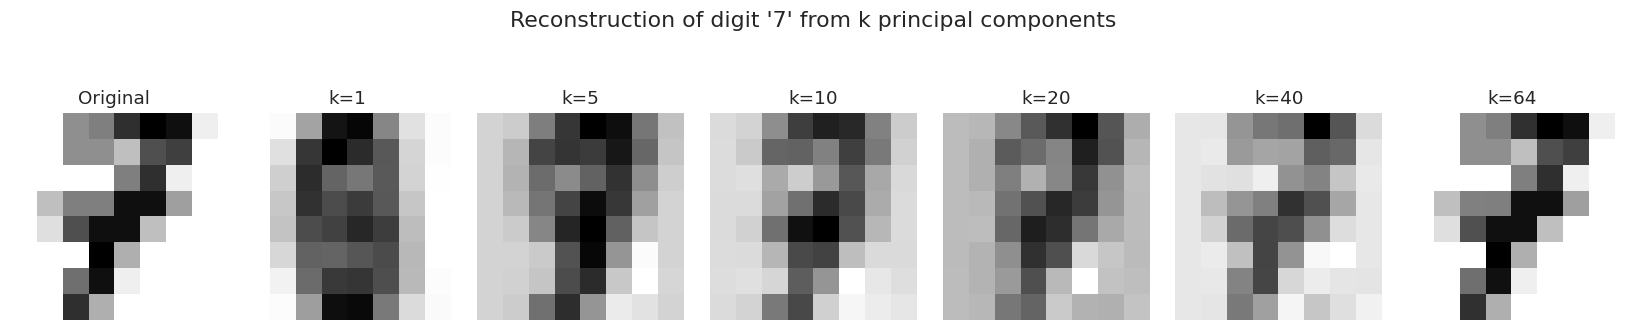

In [7]:
sample_idx = 7  # pick one digit image to reconstruct
original_image = digits.images[sample_idx]

component_counts = [1, 5, 10, 20, 40, 64]
fig, axes = plt.subplots(1, len(component_counts) + 1, figsize=(15, 2.6))

axes[0].imshow(original_image, cmap="gray_r")
axes[0].set_title("Original")
axes[0].axis("off")

for ax, k in zip(axes[1:], component_counts):
    pca_k = PCA(n_components=k, random_state=RNG)
    X_k = pca_k.fit_transform(X_scaled)
    X_reconstructed_scaled = pca_k.inverse_transform(X_k)
    X_reconstructed = scaler.inverse_transform(X_reconstructed_scaled)
    img_k = X_reconstructed[sample_idx].reshape(8, 8)
    ax.imshow(img_k, cmap="gray_r")
    ax.set_title(f"k={k}")
    ax.axis("off")

fig.suptitle(f"Reconstruction of digit '{digits.target[sample_idx]}' from k principal components", y=1.15)
plt.tight_layout()
plt.show()


With just a handful of components the digit is already recognizable — most of
the *visually important* variance lives in a small number of directions. This is the
essence of PCA-based compression.

## 5. t-SNE — Intuition

**t-SNE** takes a very different philosophy from PCA:

- PCA is **linear** and preserves **global variance/structure** — it tries to keep
  the overall shape of the data (as seen by variance) intact.
- t-SNE is **non-linear** and focuses on preserving **local structure** — it wants
  points that were *close neighbors* in high-dimensional space to remain close
  neighbors in the 2D map, even at the cost of distorting global distances.

**How it (roughly) works:**
1. In the original high-dimensional space, convert distances between points into
   *probabilities* that point *i* would pick point *j* as its neighbor (using a
   Gaussian centered on each point). Nearby points get high probability.
2. In the low-dimensional map, do the same using a heavier-tailed **Student-t
   distribution** (this is the "t" in t-SNE — it helps avoid crowding points
   together and gives more room to separate clusters).
3. Randomly initialize the low-D points, then iteratively move them so that the
   low-D neighbor probabilities match the high-D ones as closely as possible
   (minimizing KL divergence via gradient descent).

**Key hyperparameter — `perplexity`**: roughly, "how many neighbors" each point
should try to have a meaningful relationship with. Small perplexity → focuses on
very local structure (can fragment clusters); large perplexity → considers a
broader neighborhood (can blur separate clusters together). Typical values: 5–50.

**Important caveats:**
- t-SNE has **no simple `transform()` for new data** — you generally must rerun it.
- **Axes and distances between clusters are not meaningful** — only relative
  neighborhoods within the plot matter. Cluster *sizes* can also be misleading.
- It's stochastic (unless you fix `random_state`) and sensitive to perplexity.
- It's much slower than PCA, especially on large datasets.


In [8]:
# t-SNE is more expensive than PCA - for speed, run it on the raw (unscaled 0-16) pixel
# data as is standard practice for this dataset. We keep all 1797 samples; it's small enough.
print("Running t-SNE... this can take a little while.")

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=RNG,
)
X_tsne_2d = tsne.fit_transform(X)
print("Done. t-SNE output shape:", X_tsne_2d.shape)


Running t-SNE... this can take a little while.
Done. t-SNE output shape: (1797, 2)


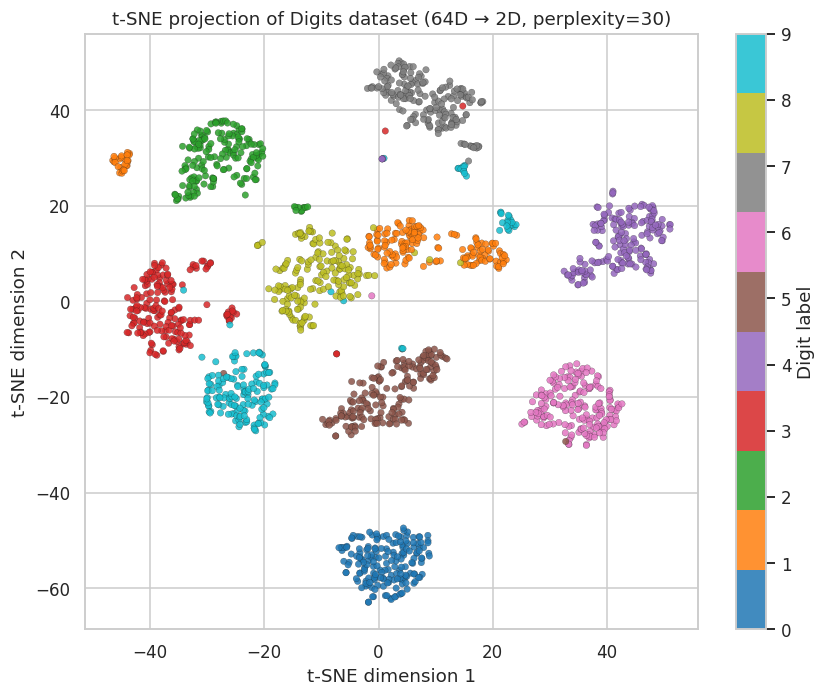

In [9]:
plt.figure(figsize=(8, 6.5))
scatter = plt.scatter(
    X_tsne_2d[:, 0], X_tsne_2d[:, 1],
    c=y, cmap="tab10", s=18, alpha=0.85, edgecolor="k", linewidth=0.15
)
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.title("t-SNE projection of Digits dataset (64D → 2D, perplexity=30)")
cbar = plt.colorbar(scatter, ticks=range(10))
cbar.set_label("Digit label")
plt.tight_layout()
plt.show()


Notice how much more cleanly the 10 digit classes separate into distinct,
tight clusters compared to the PCA plot — this is t-SNE's local-structure-preserving
non-linear approach at work. The trade-off: we can't easily project *new* points
into this same map, and the axes/distances themselves carry no direct meaning.

### 5.1 PCA vs t-SNE — side-by-side comparison

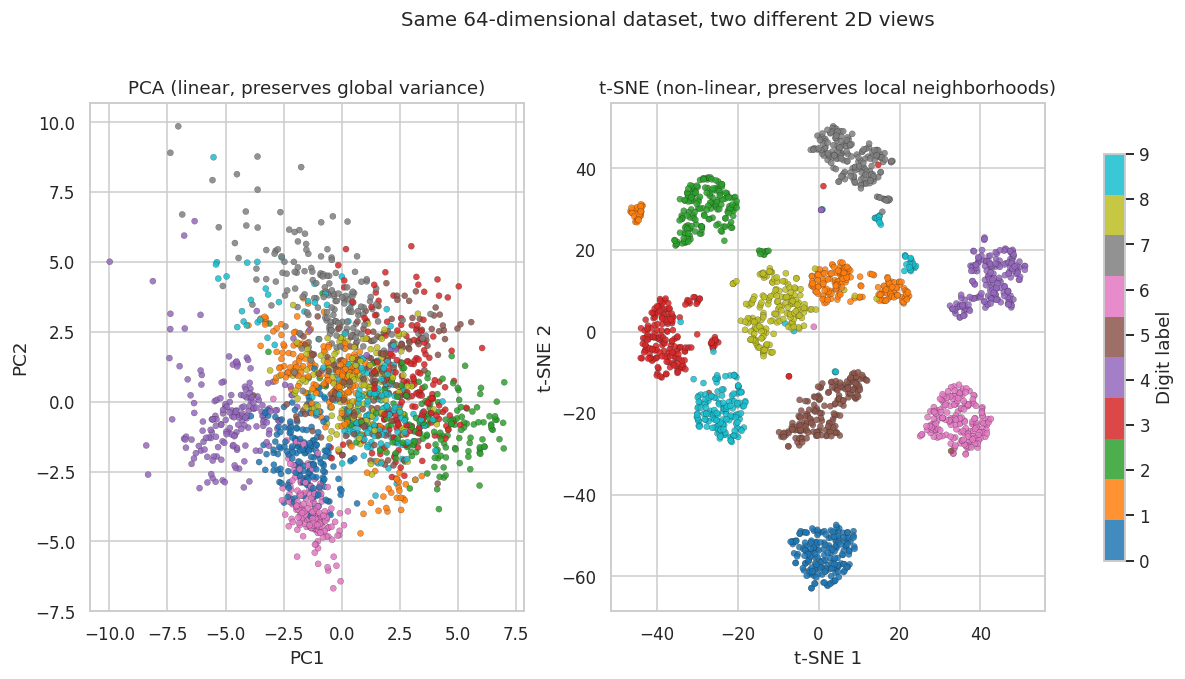

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sc0 = axes[0].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=y, cmap="tab10",
                       s=16, alpha=0.85, edgecolor="k", linewidth=0.15)
axes[0].set_title("PCA (linear, preserves global variance)")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

sc1 = axes[1].scatter(X_tsne_2d[:, 0], X_tsne_2d[:, 1], c=y, cmap="tab10",
                       s=16, alpha=0.85, edgecolor="k", linewidth=0.15)
axes[1].set_title("t-SNE (non-linear, preserves local neighborhoods)")
axes[1].set_xlabel("t-SNE 1")
axes[1].set_ylabel("t-SNE 2")

fig.colorbar(sc1, ax=axes, shrink=0.8, label="Digit label", ticks=range(10))
fig.suptitle("Same 64-dimensional dataset, two different 2D views", y=1.02, fontsize=13)
plt.show()


### 5.2 Effect of perplexity on t-SNE

Let's rerun t-SNE with several different perplexity values to see how it changes
the resulting map. (Using a subsample for speed.)


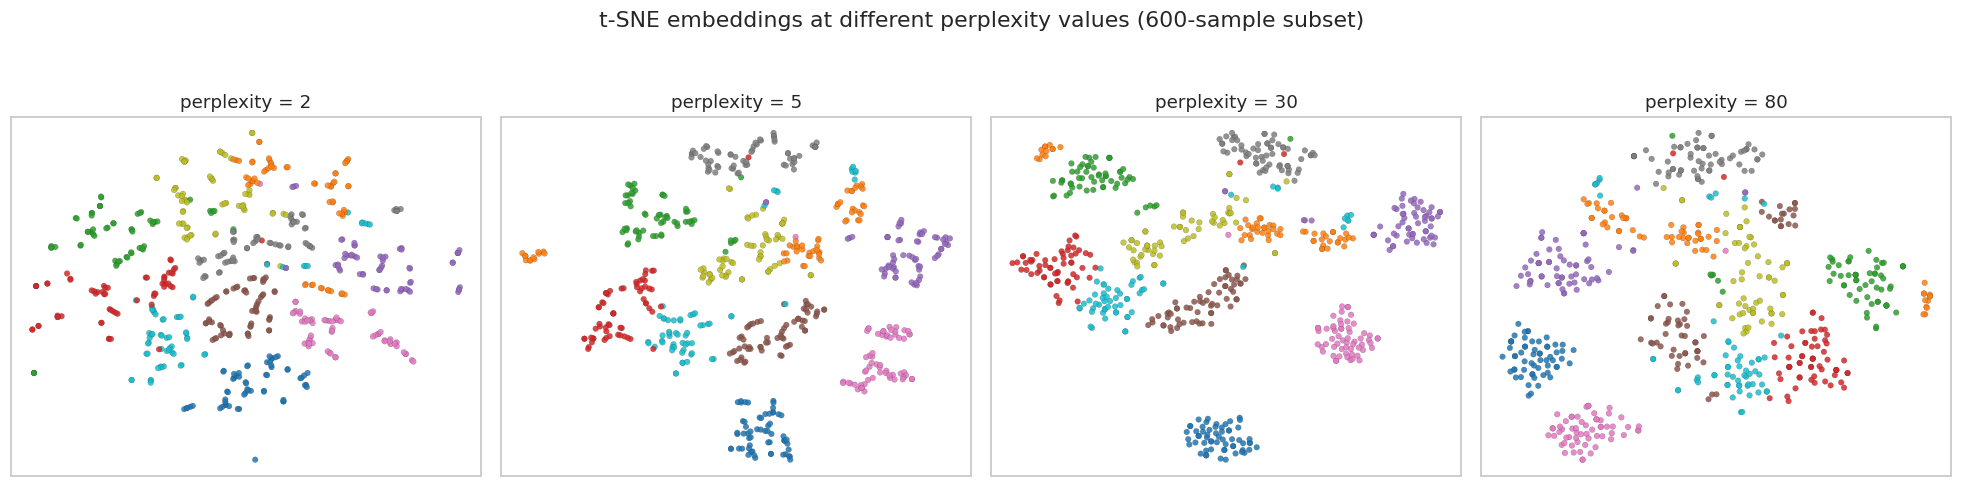

In [11]:
from sklearn.utils import resample

X_sub, y_sub = resample(X, y, n_samples=600, random_state=RNG, stratify=y)

perplexities = [2, 5, 30, 80]
fig, axes = plt.subplots(1, len(perplexities), figsize=(18, 4.2))

for ax, perp in zip(axes, perplexities):
    tsne_p = TSNE(
        n_components=2, perplexity=perp, learning_rate="auto",
        init="pca", random_state=RNG,
    )
    emb = tsne_p.fit_transform(X_sub)
    ax.scatter(emb[:, 0], emb[:, 1], c=y_sub, cmap="tab10", s=14,
               alpha=0.85, edgecolor="k", linewidth=0.1)
    ax.set_title(f"perplexity = {perp}")
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle("t-SNE embeddings at different perplexity values (600-sample subset)", y=1.05)
plt.tight_layout()
plt.show()


- **Very low perplexity (2)**: focuses on tiny local neighborhoods — clusters can
  fragment into small sub-groups / stringy shapes.
- **Moderate perplexity (5-30)**: usually the sweet spot for datasets like this —
  clear, well-separated clusters.
- **High perplexity (80)**: considers a wider neighborhood — clusters may start to
  merge or blur together, and the run takes longer.

There's no universally "correct" perplexity — it's worth trying a few values (rule
of thumb: somewhere between 5 and 50, and less than the number of samples).

## 6. Quick contrast on a simpler dataset — Iris

To reinforce the intuition on a smaller, well-known 4-dimensional dataset.

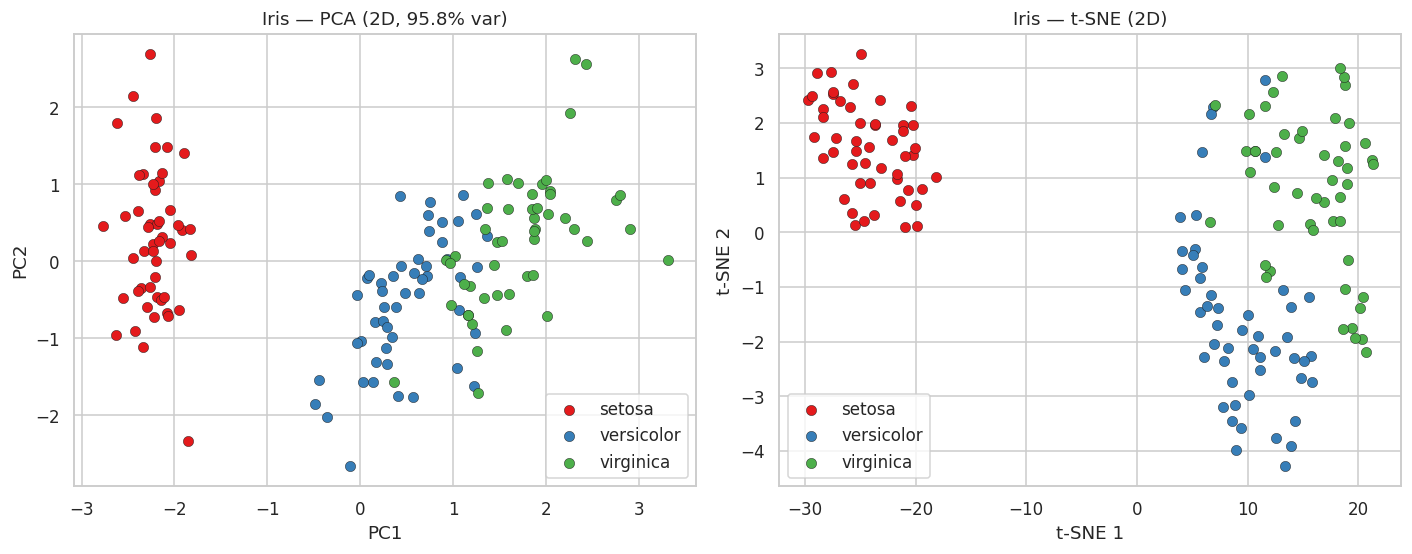

In [12]:
iris = load_iris()
Xi, yi = iris.data, iris.target
iris_names = iris.target_names

Xi_scaled = StandardScaler().fit_transform(Xi)

pca_iris = PCA(n_components=2, random_state=RNG)
Xi_pca = pca_iris.fit_transform(Xi_scaled)

tsne_iris = TSNE(n_components=2, perplexity=25, learning_rate="auto",
                  init="pca", random_state=RNG)
Xi_tsne = tsne_iris.fit_transform(Xi_scaled)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
palette = sns.color_palette("Set1", 3)

for cls in range(3):
    mask = yi == cls
    axes[0].scatter(Xi_pca[mask, 0], Xi_pca[mask, 1], label=iris_names[cls],
                     color=palette[cls], s=45, edgecolor="k", linewidth=0.3)
    axes[1].scatter(Xi_tsne[mask, 0], Xi_tsne[mask, 1], label=iris_names[cls],
                     color=palette[cls], s=45, edgecolor="k", linewidth=0.3)

axes[0].set_title(f"Iris — PCA (2D, {pca_iris.explained_variance_ratio_.sum()*100:.1f}% var)")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2"); axes[0].legend()

axes[1].set_title("Iris — t-SNE (2D)")
axes[1].set_xlabel("t-SNE 1"); axes[1].set_ylabel("t-SNE 2"); axes[1].legend()

plt.tight_layout()
plt.show()


On Iris, both methods separate *setosa* very cleanly (it's linearly separable
from the other two), while *versicolor* and *virginica* overlap somewhat in both
views since they are genuinely closer together in the original 4D feature space.

## 7. PCA vs t-SNE — summary

| Aspect | PCA | t-SNE |
|---|---|---|
| Type | Linear | Non-linear |
| Goal | Maximize preserved variance | Preserve local neighborhoods |
| Speed | Fast, scales well | Slow, expensive on large data |
| Deterministic | Yes | No (unless `random_state` fixed) |
| New/unseen data | `transform()` works directly | No direct transform — must rerun |
| Global structure | Preserved | Not reliable (only local structure meaningful) |
| Interpretability of axes | Components = directions of max variance | Axes have no intrinsic meaning |
| Typical use | Compression, preprocessing, noise reduction, quick EDA | Visual exploration / cluster discovery in 2D-3D |
| Key hyperparameter | `n_components` | `perplexity` (and `learning_rate`) |

**Rule of thumb in practice:** use PCA first (it's fast and a great general-purpose
tool, including as a preprocessing/denoising step before t-SNE on very
high-dimensional data), and use t-SNE (or UMAP) when your main goal is a
compelling, cluster-revealing 2D/3D *visualization* rather than a general-purpose
feature-reduction step for downstream modeling.


## 8. Try it yourself 🔧

Ideas to extend this notebook:
- Swap in your own dataset (just needs a numeric feature matrix `X` and optional labels `y`).
- Try `sklearn.datasets.fetch_openml('mnist_784')` for the full MNIST dataset (bigger, slower).
- Compare with **UMAP** (`pip install umap-learn`) — often faster than t-SNE with similar quality.
- Use PCA to reduce to ~30-50 dimensions first, then feed that into t-SNE — a common
  speed-up trick for larger datasets.
